In [76]:
import random
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats

In [77]:
# mettre en commentaires pour semaine 2
#random.seed(42)
#np.random.seed(42)

# Semaine $1$

## Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X)$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire  telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{N} \right)$ qui représente les forces des synapses des neurones du réseau ;
- $R(X)$ le taux de décharge que l'on assimile dans un premier temps à $tanh(X)$ (donc $R(X) \sim X$ quand $X$ est proche de $0$) ;
- ( On ne prend pas encore en compte de feedback pour l'instant)

## Stabilité du réseau

On pose $M=-I+gW$ donc : $$ \dfrac{dX}{dt} = MX$$ (pour X proche de $0$).

Si on écrit $X$ dans la base des vecteurs propres $(\vec{u_1},...,\vec{u_n})$  
$$X(t) = \sum{x_j(t) \vec{u_j}}$$
Donc : 
$$MX = M \left(\sum{x_j(t) \vec{u_j}}\right)$$
$$ \iff MX = \sum{x_j M \vec{u_j}}$$
$$\iff MX = \sum{x_j \lambda_j \vec{u_j}}$$ (avec $\lambda_j$ les valeurs propres de $M$)
Donc :
$$ \dfrac{dX}{dt} = \sum{x_j \lambda_j \vec{u_j}}$$


Donc : $$x_i(t) = x_0 e^{\lambda_i t}  \vec{u_j}$$

Donc pour un neurone $i$,  $\lim_{t \to +\infty} x_i(t)$ dépend de la partie réelle de $\lambda_i$ : si $\lambda_i<0$, $x_i(t)$ va converger vers $0$. Si tous les neurones respectent cette conditions, le réseau va se stabiliser. Sinon le réseau ne va pas être stable.

Or comme on a posé $M = -I+gW$ on peut déduire des valeurs propres de $W$ les valeurs propres de $M$ : 
$$Mv = (gW - I)v$$
$$ \iff Mv = gWv - v$$
$$ \iff Mv = g\mu v -v$$ ( avec $\mu$ valeur propre de $W$ et $v$ le vecteur propre associé, donc $Wv=\mu v$)
$$ \iff Mv = (-1+g\mu)v$$

Donc les valeurs propres de M valent $-1+g\mu$ avec $\mu$ les valeurs propres de $W$. Les valeurs propres de $W$ étant concentrées dans le cercle de rayon $1$ centré en $0$, tous les $\lambda$ seront négatifs si $g<1$. 

Donc si $g<1$ le réseau est stable et sinon le réseau est instable.

-----------

Si on ajoute une entrée I au modèle et qu'on a :
$$ \dfrac{dX}{dt} = -X + gWR(X) + I$$
Alors on a : 
$$ \dfrac{dX}{dt} = \sum{x_j \lambda_j \vec{u_j}} + \sum{I_j} \vec{u_j}$$
Et donc :
$$ x_i(t) = (x_i(0)+ \dfrac{I_i}{\lambda_i}) e^{\lambda_i t}  \vec{u_i} - \dfrac{I_i}{\lambda_i}$$
Et si $g<1$, les $x_i$ convergent vers les $-\dfrac{I_i}{\lambda_i}$

## Exemples

On fixe le nombre d'unités de type neuronal avec lequel on veut travailler :

In [78]:
n = 1000

On construit une matrice aléatoire $W$ telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{N} \right)$

In [79]:
def W(n):
    W = [[random.gauss(0,1/np.sqrt(n)) 
          for j in range (n)] for i in range (n)]
    W = np.array(W)
    return W

In [80]:
W(n) #exemple

array([[ 0.01971534, -0.05554754, -0.00024159, ..., -0.03175864,
         0.02185352, -0.00550404],
       [ 0.08218197, -0.08585691,  0.00139891, ..., -0.02575798,
        -0.02816254,  0.04948411],
       [ 0.04410508,  0.01127469, -0.0074417 , ...,  0.02058358,
        -0.03888542, -0.00015794],
       ...,
       [-0.02750762, -0.03831356,  0.04619027, ...,  0.00502645,
        -0.03942159,  0.05327427],
       [-0.03356694,  0.00361271, -0.0004431 , ...,  0.00949755,
         0.00683352,  0.00516327],
       [-0.02112801, -0.04616794, -0.02932528, ..., -0.00088742,
        -0.00696706, -0.03210051]])

On calcule les valeurs propres de $W$ :

In [81]:
def valeurs_propres(W):
    V = np.linalg.eigvals(W)
    return V

In [82]:
V = valeurs_propres(W(n))

On les trace dans le plan complexe :

In [83]:
def graphique_eigvals_W(V):
    Atcd,Images = V.real,V.imag
    plt.figure(figsize =(8,6))
    plt.grid()
    plt.scatter(V.real,V.imag, label="Valeurs propres de W")
    plt.xlim(-2, 2)
    plt.axhline(0, color="black")
    plt.axvline(0, color="black")
    theta = np.linspace(0, 2*np.pi, 1000)
    plt.plot(np.cos(theta),np.sin(theta),color="black")
    plt.axis('equal')
    plt.xlabel("partie réelle")
    plt.ylabel("partie imaginaire")
    plt.legend()
    plt.show()

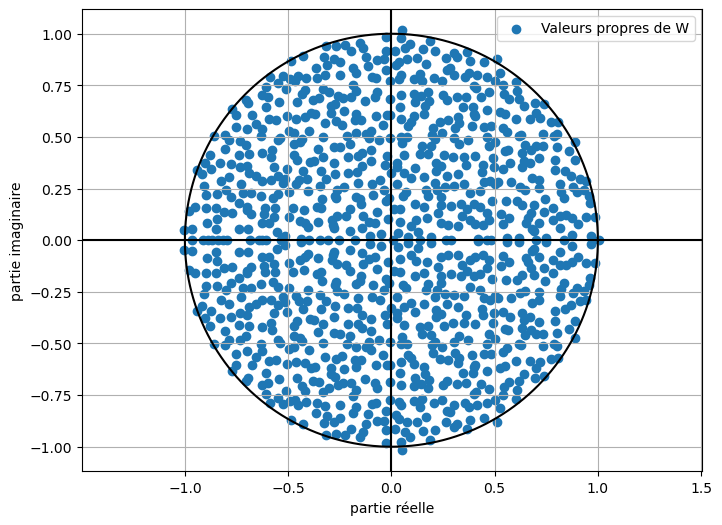

In [84]:
graphique_eigvals_W(V)

On voit que les valeurs propres de $W$ se concentrent dans le cercle de rayon $1$ centré en $0$.

On utilise le fait que les valeurs propres de M valent $-1+g\mu$ avec $\mu$ les valeurs propres de $W$.

In [85]:
def eigvals_M(V,g):
    V_m = -1+ g * V
    return V_m

In [94]:
V_m = eigvals_M(V,0.6)

In [95]:
def graphique_eigvals_M(V):
    Atcd,Images = V.real,V.imag
    plt.figure(figsize =(8,8))
    plt.grid()
    plt.scatter(V.real,V.imag, label="Valeurs propres de M")
    plt.xlim(-2, 2)
    plt.ylim(-2, 2)
    plt.axis("equal")
    plt.axhline(0, color="black")
    plt.axvline(0, color="black")
    theta = np.linspace(0, 2*np.pi, 1000)
    plt.plot(np.cos(theta)-1,np.sin(theta),color="black")
    plt.axis('equal')
    plt.xlabel("partie réelle")
    plt.ylabel("partie imaginaire")
    plt.legend()
    plt.savefig("spectre_M.pdf", bbox_inches="tight") 
    plt.show()

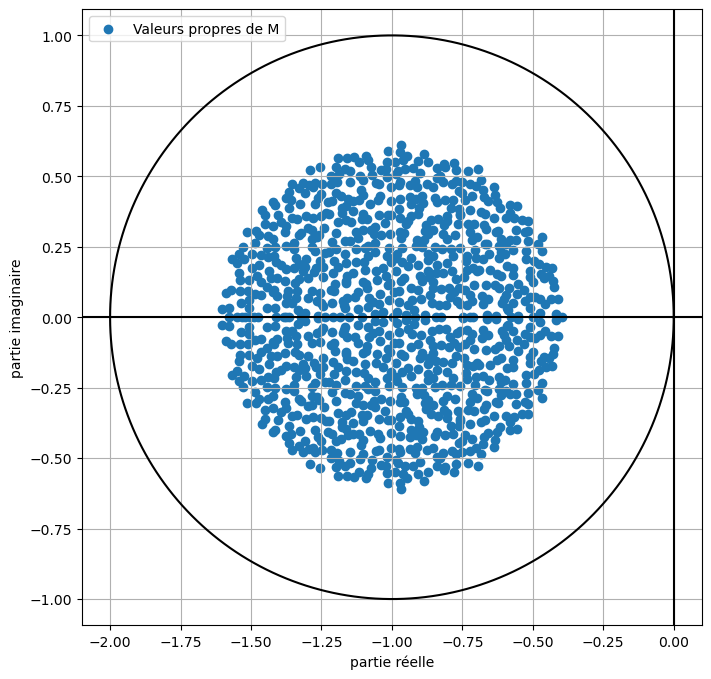

In [96]:
graphique_eigvals_M(V_m)

On voit donc que si $g<1$, les valeurs propres de $M$ auront une partie réelle et une partie imaginaire négatives.

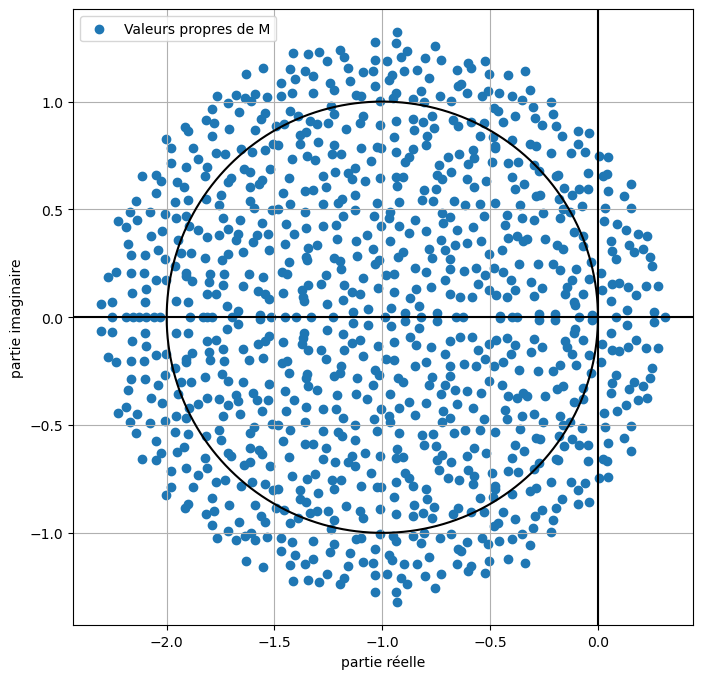

In [91]:
V_m = eigvals_M(V,1.3)
graphique_eigvals_M(V_m)

On voit que si $g>1$ certaines valeurs propres de $M$ auront une partie réelle positive. 

## Simulation

In [99]:
def f(X,g,W) :
    R = np.tanh(X)
    return -X+g* ( W @ R)

In [100]:
def exemple_X(n):
    X = [random.uniform(-0.5,0.5) for i in range(n)]
    X = np.array(X)
    return X

In [101]:
X = exemple_X(n)

In [102]:
def Euler_O1(f,t_0,X_0,h,T,g,W):
    Images_Euler = [X_0]
    Atcd_Euler = [t_0]
    X = X_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * f(X,g,W) + X  
        t += h
        Images_Euler.append(X)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [105]:
def graph_O1(f,t_0,X_0,h,T,g,W):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler] )

    plt.savefig("x_m.pdf", bbox_inches="tight") 
    plt.show()

Exemple avec $g=0,6$ :

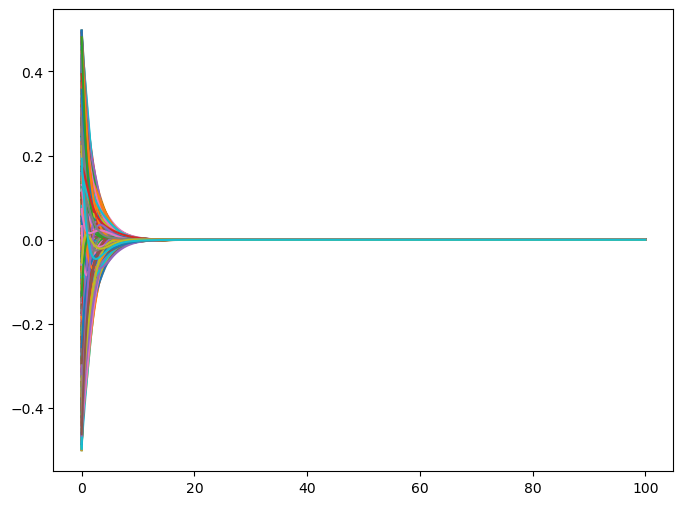

In [104]:
graph_O1(f,0,exemple_X(n),0.01,100,0.6,W(n))

Exemple avec $g=1,3$ :

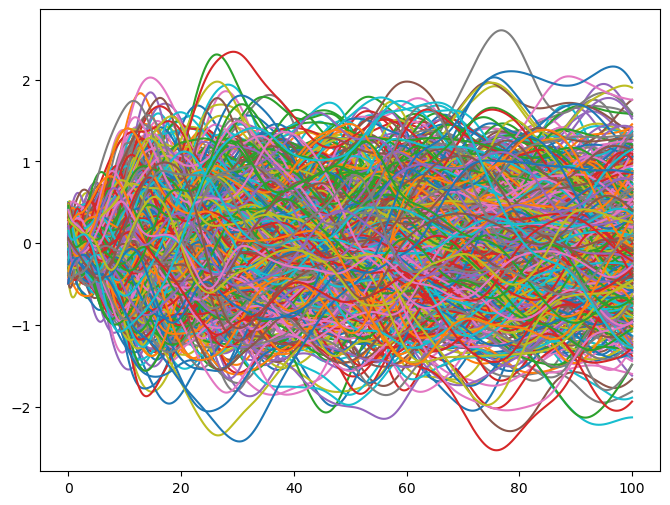

In [106]:
graph_O1(f,0,exemple_X(n),0.01,100,1.3,W(n))

## Avec $R(X)=X$ comme taux de décharge

Avec $R(X) = X$ comme taux de décharge, les valeurs de X ne sont plus saturées :

In [22]:
def f(X,g,W) :
    return -X+g* ( W @ X)

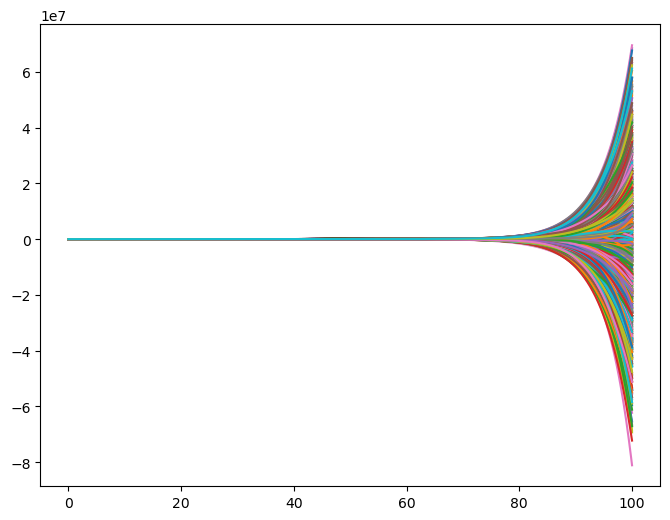

In [23]:
graph_O1(f,0,exemple_X(n),0.01,100,1.2,W(n))

# Semaine $2$

## Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X) + B$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{N} \right)$ qui représente les forces des synapses des neurones du réseau. On conservera uniquement les $W_{i,j} < 0$ (on se place dans le cadre d'un réseau avec uniquement des synapses inhibitrices) ; 
- $R(X)$ le taux de décharge que l'on assimile a la fonction ReLU ;
- $B$ une entrée externe constante (activatrice, avec des valeurs positives)

--------------
En posant $M=gWD$, avec $D$ la matrice diagonale dont les coefficients diagonaux valent $1$ si $x_i>0$ et $0$ sinon on a :
$$ \dfrac{dX}{dt} = MX+B$$
On peut poser de la même manière $ MX = \sum{x_j \lambda_j \vec{u_j}}$, donc :
$$ \dfrac{dx_i}{dt} = x_i \lambda_i + B_i $$
Donc :
$$ x_i = (x_0 + \dfrac{B_i}{\lambda_i}) e^{\lambda_i t} - \dfrac{B_i}{\lambda_i}$$

Donc, si $\lambda_i <0$ $x_i$ va tendre vers $\dfrac{-B_i}{\lambda_i}$

## Simulation

On crée $W$ avec uniquement des synapses inhibitrices (pour $n$ unités de type neuronal) :

In [24]:
def W_inhib(n):
    W = []
    w = []
    i=0
    for j in range(n):
        while i<n :
            x = random.gauss(0,1/np.sqrt(n))
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W

On défini le taux de décharge : 

In [25]:
def R_relu(X) :
    return np.maximum(X,0)

On défini $B$ excitateur :

In [26]:
def B(n):
    graine = random.Random(42) # random.seed fixe la graine pour tout
    return np.array([graine.uniform(0,0.5) for i in range (n)])
    

In [27]:
g = 1.2
t_0 = 0
W = W_inhib(n)
B_n = B(n)
h = 0.01
T = 100

In [28]:
#print (W)

On écrit l'équation différentielle :

In [29]:
def f(X,g,W,B_n) :
    return -X+g* ( W @ R_relu(X)) + B_n

In [30]:
#f(X,g,W,B_n)

In [31]:
def Euler_O1(f,t_0,X_0,h,T,g,W,B_n):
    Images_Euler = [X_0]
    Atcd_Euler = [t_0]
    X = X_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * f(X,g,W,B_n) + X  
        t += h
        Images_Euler.append(X)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [32]:
#Euler_O1(f,t_0,X,h,T,g,W,B_n)

In [33]:
def graph_O1(f,t_0,X_0,h,T,g,W,B_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler] )
    plt.show()

On trace le graphique :

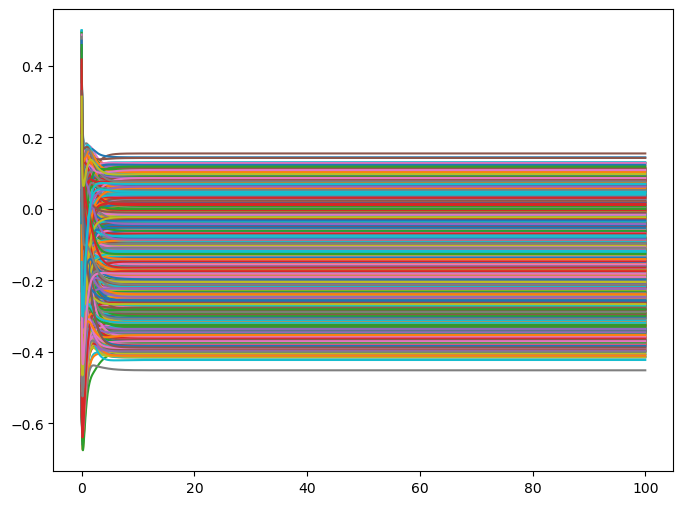

In [34]:
graph_O1(f,t_0,X,h,T,g,W,B_n)

On voit que le réseau arrive à un état d'équilibre où $X = gWR(X) + B$ (A l'équilibre $ \dfrac{dX}{dt} = 0$ donc $X = gWR(X) + B$) :

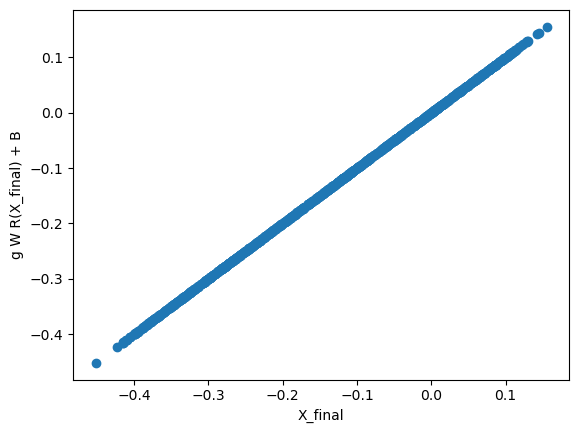

In [35]:
Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X,h,T,g,W,B_n)
X_final = Images_Euler[-1]
X_equilibre = g * W @ R_relu(X_final) + B_n

plt.scatter(X_final, X_equilibre)
plt.xlabel("X_final")
plt.ylabel("g W R(X_final) + B")
plt.show()

## Valeurs propres

On introduit $D$, la matrice diagonale dont les coefficients diagonaux valent $1$ si $x_i>0$ et $0$ sinon :

In [36]:
def D(X):
    D = [[0 for j in range (len(X))] for i in range (len(X))]
    for k in range (len(X)):
        if X[k] > 0 :
            D[k][k] = 1
    return D

In [37]:
D=D(X)

On calcule les valeurs propres de $WD$ :

In [38]:
WD = W @ D
V= valeurs_propres(WD)

On trace les valeurs propres de $WD$ :

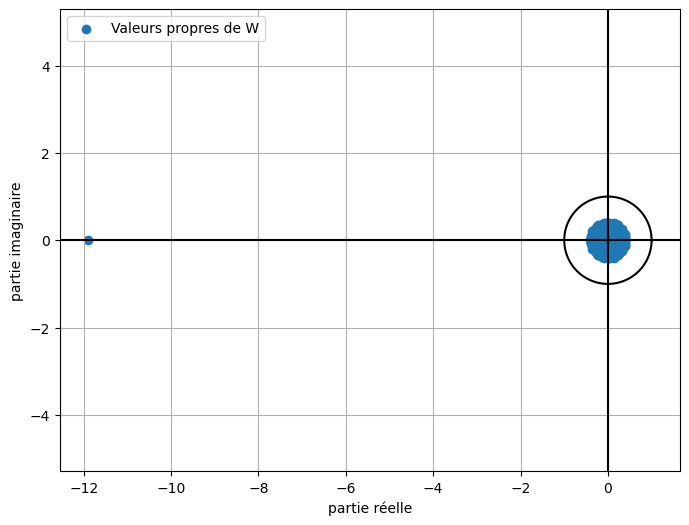

In [39]:
graphique_eigvals_W(V)

On trace les valeurs propres de $M$ :

In [40]:
V_m = eigvals_M(V,g)

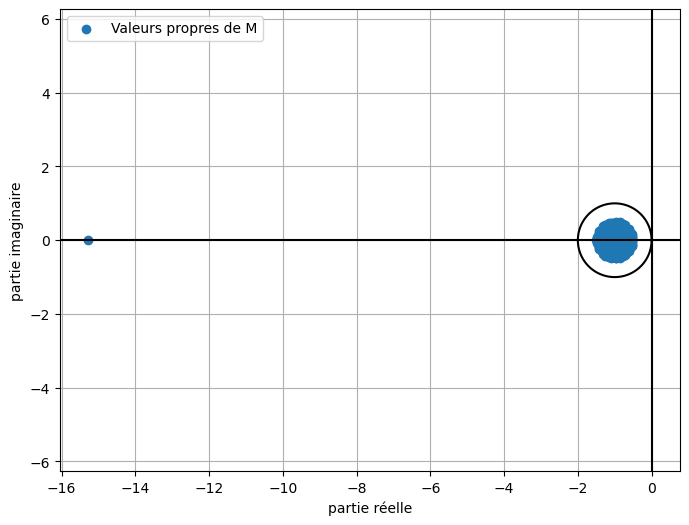

In [41]:
graphique_eigvals_M(V_m)

In [42]:
def graph_O1_lim(f,t_0,X_0,h,T,g,W,B_n,V):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler] )
        plt.axhline(y = - B_n[i] / V[i],color = "black", alpha = 0.3)
    plt.show()

C:\Users\15s-eq2042\AppData\Local\Temp\ipykernel_23896\2907353507.py:6: RuntimeWarning: divide by zero encountered in scalar divide
  plt.axhline(y = - B_n[i] / V[i],color = "black", alpha = 0.3)
C:\Users\15s-eq2042\AppData\Local\Temp\ipykernel_23896\2907353507.py:6: RuntimeWarning: invalid value encountered in scalar divide
  plt.axhline(y = - B_n[i] / V[i],color = "black", alpha = 0.3)
C:\Users\15s-eq2042\anaconda3\Lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


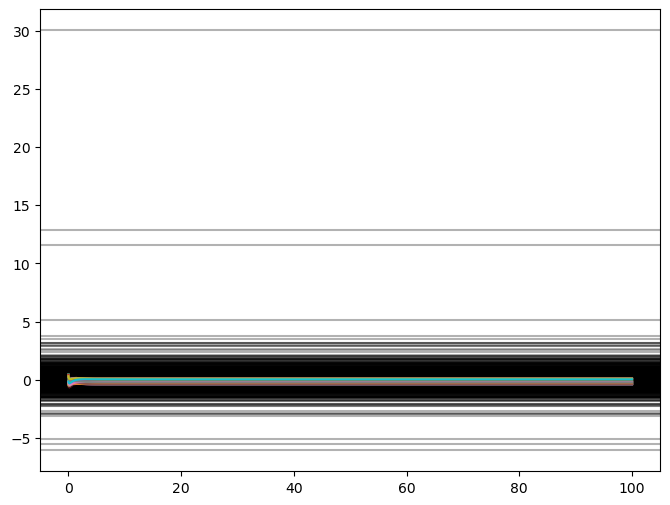

In [43]:
graph_O1_lim(f,t_0,X,h,T,g,W,B_n,V)

## Histogrammes

On trace l'histogramme pour regarder la distribution des $x_i$ (comparaison avec une loi normale et uniforme) à la fin de la simulation :

In [44]:
Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X,h,T,g,W,B_n)
mu = np.mean(Images_Euler[-1])

In [45]:
maxi = np.max(Images_Euler[-1])

In [46]:
mini = np.min(Images_Euler[-1])

In [47]:
sigma = np.std(Images_Euler[-1]) #écart-type

In [48]:
def histogramme_X(f,t_0,X_0,h,T,g,W,B_n,mu,sigma):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 30,density=True)

    x = np.linspace(mini,maxi,1000)
    plt.plot(x, scipy.stats.norm.pdf(x, mu, sigma))
    plt.plot(x, scipy.stats.uniform.pdf(x, mini, maxi-mini))

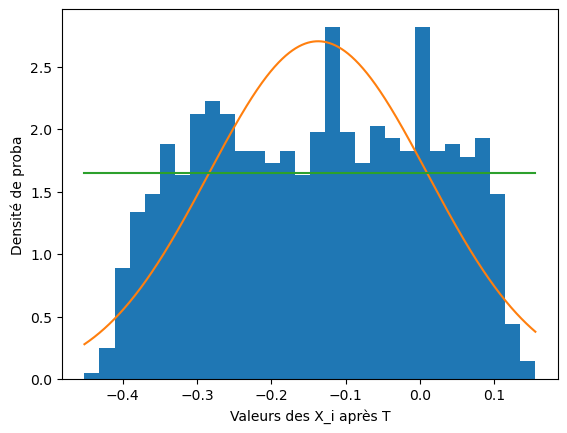

In [49]:
histogramme_X(f,t_0,X,h,T,g,W,B_n,mu,sigma)

On trace l'histogramme pour regarder la répartition des taux de décharge après la simulation :

In [50]:
def histogramme_R(f,t_0,X_0,h,T,g,W,B_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
    plt.xlabel("Valeurs des R(X_i) après T")
    plt.ylabel("Effectifs")
    plt.hist(R_relu(Images_Euler[-1]), bins = 30)

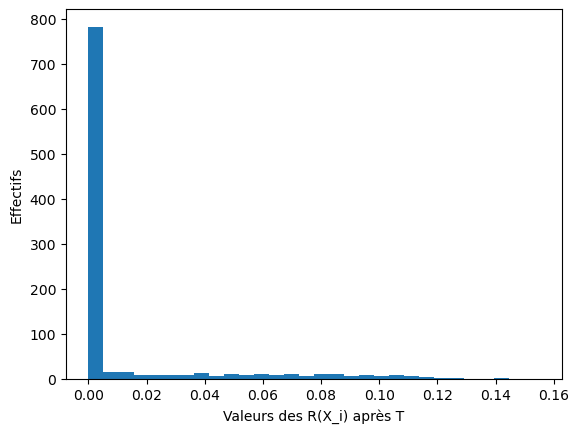

In [51]:
histogramme_R(f,t_0,X,h,T,g,W,B_n)

On voit qu'il n'y a quasiment plus de décharge.

On superpose les histogrammes de plusieurs simulation afin de voir si les distributions se superposent (et on compare à une loi normale et uniforme) :

In [52]:
def histogramme_comp_diff_W(f,t_0,X_0,h,T,g,W,B_n):
    liste_mu = []
    liste_sigma = []
    liste_mini = []
    liste_maxi = []
    for i in range (50):
        W = W_inhib(n)
        Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
        plt.hist(Images_Euler[-1], bins = 50, color = "blue", alpha = 0.1,density = True)
        liste_mu.append(np.mean(Images_Euler[-1]))
        liste_sigma.append(np.std(Images_Euler[-1]))
        liste_mini.append(np.min(Images_Euler[-1]))
        liste_maxi.append(np.max(Images_Euler[-1]))
    mu = np.mean(liste_mu)
    sigma = np.mean(liste_sigma)
    mini = np.mean(liste_mini)
    maxi = np.mean(liste_maxi)
    x = np.linspace(mini,maxi,1000)
    plt.plot(x,scipy.stats.norm.pdf(x,mu,sigma),color="red")
    plt.plot(x,scipy.stats.uniform.pdf(x,mini,maxi-mini),color = "green")
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Effectifs")
    

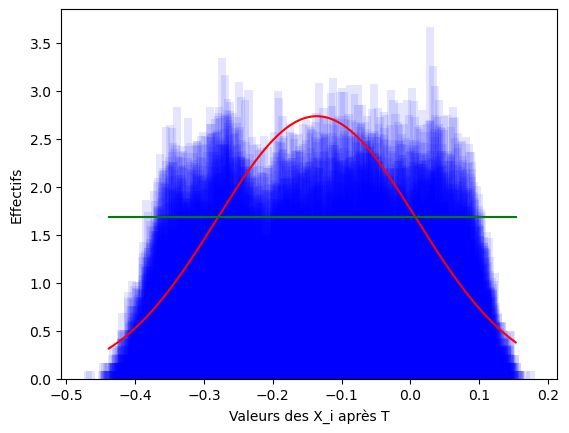

In [53]:
histogramme_comp_diff_W(f,t_0,X,h,T,g,W,B_n)

## Modéliser la distribution de $X$

In [54]:
# faire une fonction pour densité de proba de Images_Euler[-1]
def centre_bins(donnees):
    y_hist, bin_edges = np.histogram(donnees, bins=30, density=True)
    x_hist = (bin_edges[:-1] + bin_edges[1:]) / 2
    return x_hist,y_hist

In [55]:
#centre_bins(Images_Euler[-1])

On essaie de trouver la meilleure approximation parmi plusieurs lois :

In [56]:
dist_names = ['norm', 'beta', "truncnorm"]

In [57]:
def meilleure_loi(donnees, dist_names):
    
    sse = 10000
    x_hist,y_hist = centre_bins(donnees)
    
    for name in dist_names:

    	# Modéliser
    	dist = getattr(scipy.stats, name)
    	param = dist.fit(donnees)

    	# Paramètres
    	loc = param[-2]
    	scale = param[-1]
    	arg = param[:-2]

    	# PDF
    	pdf = dist.pdf(x_hist, *arg, loc=loc, scale=scale)
    	# SSE
    	model_sse = np.sum((y_hist - pdf)**2)

    	# Si le SSE est diminué, enregistrer la loi
    	if model_sse < sse :
    		best_pdf = pdf
    		sse = model_sse
    		best_loc = loc
    		best_scale = scale
    		best_arg = arg
    		best_name = name
    return best_pdf, sse, best_loc, best_scale, best_arg,best_name

# A CORRIGER : POUR SSE IL FAUT COMP 2 DENSITES DE PROBA (et pas images_euler)

On teste pour une simulation :

In [58]:
meilleure_loi(Images_Euler[-1],dist_names)

(array([0.26401161, 0.57106411, 0.82506634, 1.04630452, 1.2423455 ,
        1.41712861, 1.57303124, 1.71160865, 1.83392494, 1.94072241,
        2.03251643, 2.10965159, 2.17233601, 2.22066206, 2.25461797,
        2.27409259, 2.2788744 , 2.26864479, 2.24296496, 2.20125476,
        2.14276037, 2.06650519, 1.97121427, 1.85519364, 1.71612798,
        1.55071591, 1.35394475, 1.11742247, 0.82451994, 0.42723987]),
 4.0722604969352565,
 -0.4533319000659499,
 0.6097578674815833,
 (1.8048563433947846, 1.673886541895588),
 'beta')

In [59]:
best_pdf, sse, best_loc, best_scale, best_arg,best_name = meilleure_loi(Images_Euler[-1],dist_names)

dist_name = best_name
dist = getattr(scipy.stats, dist_name) #getattr pour appliquer la fonction dont le nom est dans la chaine de carac de la variable
param = dist.fit(Images_Euler[-1])

loc = param[-2] # décale horizontalement 
scale = param[-1] # crtl étalement
arg = param[:-2] # param de forme

x = np.linspace(mini,maxi,1000)

pdf = dist.pdf(x, loc=loc, scale=scale, *arg) # * pour passer chaque argument du tuple en argument séparé


def histogramme(f,t_0,X_0,h,T,g,W,B_n,loc,scale,arg,x):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 30,density=True)
    plt.plot(x, pdf, label=dist_name) 

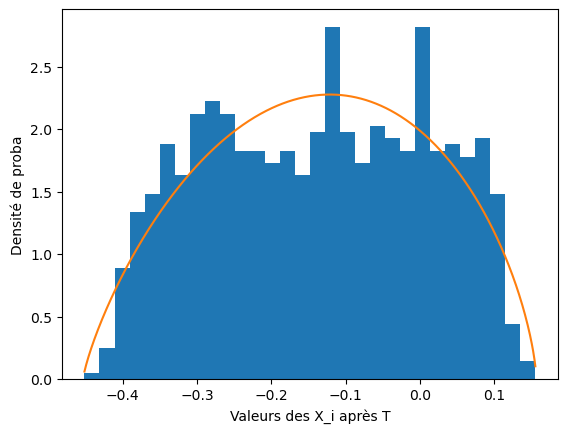

In [60]:
histogramme(f,t_0,X,h,T,g,W,B_n,loc,scale,arg,x)

On essaie pour plusieurs simulations :

In [61]:
def histogramme_comp_diff_lois_W(f,t_0,X_0,h,T,g,W,B_n,dist_names):
    lois = []
    
    for i in range (50):
        W = W_inhib(n)
        Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,B_n)
        plt.hist(Images_Euler[-1], bins = 50, color = "blue", alpha = 0.1,density = True)
        
        best_pdf, sse, best_loc, best_scale, best_arg,best_name = meilleure_loi(Images_Euler[-1],dist_names)#
        dist = getattr(scipy.stats, best_name)
        param = dist.fit(Images_Euler[-1])
        loc = param[-2]
        scale = param[-1] 
        arg = param[:-2]
        mini = np.min(Images_Euler[-1])
        maxi = np.max(Images_Euler[-1])
        x = np.linspace(mini,maxi,1000)
        pdf = dist.pdf(x, loc=loc, scale=scale, *arg)
        plt.plot(x, pdf, label=best_name)
        lois.append(best_name)
        
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Effectifs")

    return lois

['beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta',
 'beta']

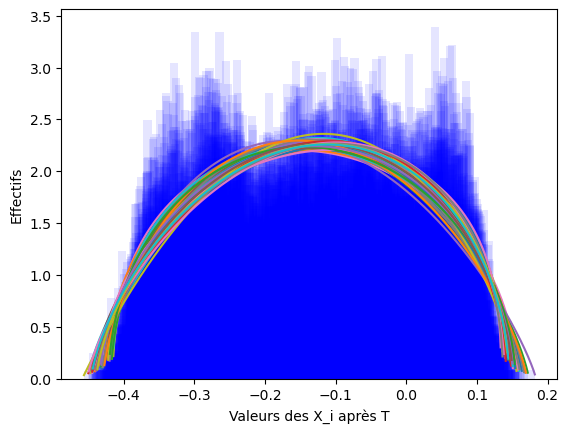

In [62]:
histogramme_comp_diff_lois_W(f,t_0,X,h,T,g,W,B_n,dist_names)